## 01 - Dataset exploration 

### (Specification 1)


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data_loader, metrics, prompts
config.ensure_dirs()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SPLIT = "test"   #"dev" for development (100 questions from validation split); "test" for the testing (300 questions from test split)
print("model:", config.MODEL, "| server:", config.BASE_URL)

model: mistral:7b | server: http://localhost:11434/v1


In [2]:
print("raw split sizes:", data_loader.download_arc())
manifest = data_loader.build_samples()
print({k: (v["source_split"], v["n"]) for k, v in manifest.items()})

raw split sizes: {'train': 1119, 'validation': 299, 'test': 1172}
{'dev': ('validation', 100), 'test': ('test', 300)}


### Length and option statistics (sampled sets vs. the full official splits)

In [3]:
raw = {s: data_loader.load_raw(s) for s in ("train", "validation", "test")}
dev, test = data_loader.load_sampled("dev"), data_loader.load_sampled("test")

def frame(qs, name):
    return pd.DataFrame({
        "set": name,
        "q_words": [len(data_loader.tokenize_words(q.question)) for q in qs],
        "q_chars": [len(q.question) for q in qs],
        "n_options": [q.n_options for q in qs],
        "mean_option_words": [np.mean([len(data_loader.tokenize_words(o)) for o in q.options]) for q in qs],
        "gold": [q.answer for q in qs],
    })

df = pd.concat([frame(raw["train"], "raw-train"), frame(raw["validation"], "raw-validation"),
                frame(raw["test"], "raw-test"), frame(dev, "dev (sampled)"), frame(test, "test (sampled)")], ignore_index=True)
summary = df.groupby("set")[["q_words", "q_chars", "n_options", "mean_option_words"]].agg(["mean", "median", "max"]).round(2)
summary.to_csv(config.TABLES_DIR / "dataset_length_stats.csv")
summary

q_words             q_chars             n_options            mean_option_words              
                  mean median  max    mean median  max      mean median max              mean median    max
set                                                                                                        
dev (sampled)    22.72   19.0   96  134.69  107.0  560      4.01    4.0   5              4.64   4.25  13.00
raw-test         22.56   19.0  131  131.57  112.0  831      4.00    4.0   5              4.93   4.75  28.25
raw-train        21.76   18.0  110  126.37  106.0  683      4.00    4.0   5              4.82   4.50  18.50
raw-validation   22.84   20.0   96  133.83  113.0  560      3.99    4.0   5              4.86   4.75  25.00
test (sampled)   22.82   19.0   90  132.01  111.0  501      4.00    4.0   5              5.05   5.00  16.25

Number of options per question (share of set):
n_options           3      4      5
set                                
dev (sampled)   0.000  0.990  0.010
raw-test        0.003  0.994  0.003
raw-train       0.001  0.998  0.001
raw-validation  0.010  0.987  0.003
test (sampled)  0.003  0.990  0.007

Gold letter distribution (share of set) - check for position bias:
gold                A      B      C      D      E
set                                              
dev (sampled)   0.200  0.230  0.260  0.300  0.010
raw-test        0.227  0.265  0.265  0.243  0.000
raw-train       0.214  0.265  0.260  0.262  0.000
raw-validation  0.214  0.244  0.261  0.278  0.003
test (sampled)  0.230  0.270  0.257  0.243  0.000


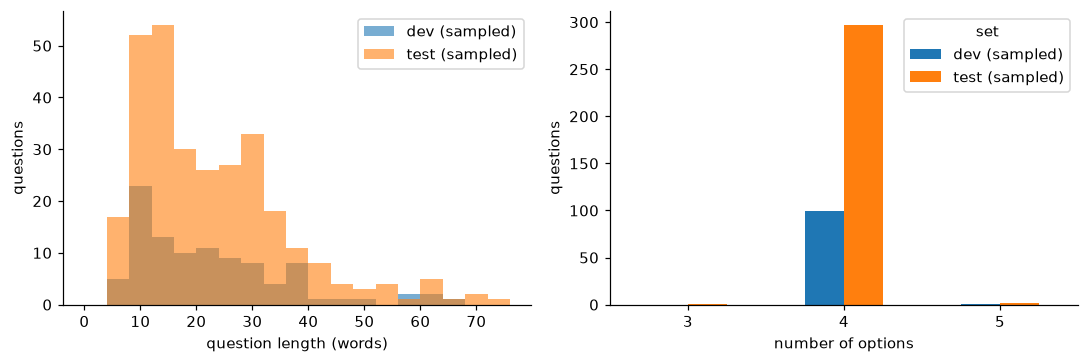

In [4]:
print("Number of options per question (share of set):")
print(pd.crosstab(df["set"], df["n_options"], normalize="index").round(3))
print("\nGold letter distribution (share of set) - check for position bias:")
print(pd.crosstab(df["set"], df["gold"], normalize="index").round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for name in ("dev (sampled)", "test (sampled)"):
    ax[0].hist(df[df.set == name].q_words, bins=range(0, 80, 4), alpha=0.6, label=name)
ax[0].set(xlabel="question length (words)", ylabel="questions"); ax[0].legend()
cnt = df[df.set.isin(["dev (sampled)", "test (sampled)"])].groupby(["n_options", "set"]).size().unstack(fill_value=0)
cnt.plot.bar(ax=ax[1], rot=0); ax[1].set(xlabel="number of options", ylabel="questions")
plt.tight_layout(); plt.savefig(config.PLOTS_DIR / "01_length_and_options.png"); plt.show()

### Vocabulary and common concepts (using NLTK)

400 questions | 9119 word tokens | 1994 distinct
stopwords / short tokens removed: 47.2% of tokens -> 1861 distinct content words

Most frequent content words in question stems: [('water', 71), ('likely', 60), ('best', 53), ('would', 51), ('following', 36), ('energy', 30), ('earth', 29), ('student', 29), ('one', 27), ('plant', 27), ('different', 27), ('students', 26), ('statement', 24), ('sun', 23), ('plants', 23), ('many', 19), ('two', 18), ('type', 18), ('explains', 17), ('found', 16), ('surface', 16), ('make', 16), ('cell', 16), ('temperature', 16), ('organisms', 15)]

Most frequent bigrams (stopwords kept): [('of the', 97), ('which of', 67), ('most likely', 56), ('in the', 51), ('is the', 38), ('of these', 38), ('of a', 37), ('the following', 36), ('in a', 34), ('to the', 27), ('from the', 26), ('what is', 24), ('the sun', 23), ('which statement', 22), ('the most', 22)]

Question openers: {'which': np.int64(222), 'what': np.int64(61), 'other': np.int64(56), 'how': np.int64(26), 'wh

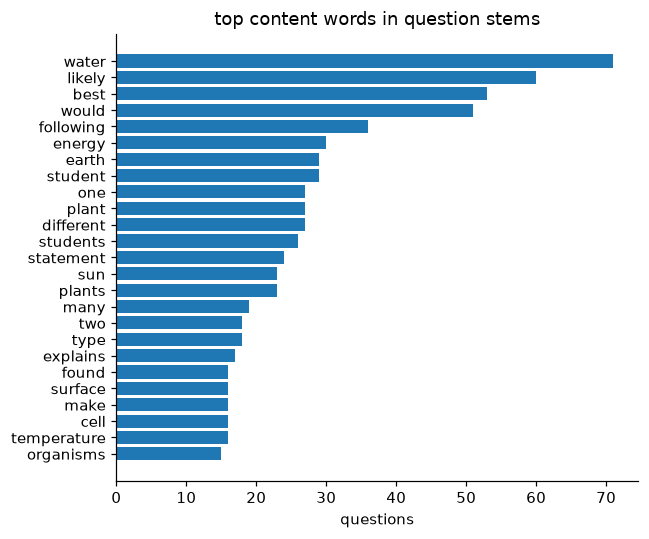

In [5]:
qs = dev + test
sw = data_loader.get_stopwords()
all_tokens = [w for q in qs for w in data_loader.tokenize_words(q.question)]
content = [w for w in all_tokens if w not in sw and len(w) > 2]
print(f"{len(qs)} questions | {len(all_tokens)} word tokens | {len(set(all_tokens))} distinct")
print(f"stopwords / short tokens removed: {1 - len(content) / len(all_tokens):.1%} of tokens -> {len(set(content))} distinct content words")

fd = data_loader.word_freqdist(qs)
top = fd.most_common(25)
print("\nMost frequent content words in question stems:", top)
print("\nMost frequent bigrams (stopwords kept):", [(" ".join(b), n) for b, n in data_loader.top_bigrams(qs, 15)])
print("\nQuestion openers:", dict(pd.Series([data_loader.wh_word(q) for q in qs]).value_counts()))

fig, ax = plt.subplots(figsize=(6, 5))
w, n = zip(*top[::-1]); ax.barh(w, n); ax.set(xlabel="questions", title="top content words in question stems")
plt.tight_layout(); plt.savefig(config.PLOTS_DIR / "01_top_words.png"); plt.show()

### Manual categorisation (factual / causal / comparison / numerical)

In [6]:
import random
CSV = config.SAMPLED_DIR / "manual_categories.csv"
if not CSV.exists():
    rng = random.Random(config.SEED)
    sample = rng.sample(dev, 40)
    pd.DataFrame({
        "id": [q.id for q in sample],
        "question": [q.question for q in sample],
        "options": [" | ".join(f"{l}. {o}" for l, o in zip(q.letters, q.options)) for q in sample],
        "manual_label": "",
    }).to_csv(CSV, index=False)
    print("wrote template:", CSV)

cat = pd.read_csv(CSV).fillna("")
labelled = cat[cat.manual_label.str.strip() != ""]
print(f"{len(labelled)}/{len(cat)} questions labelled")
if len(labelled):
    print(labelled.manual_label.value_counts())

40/40 questions labelled
manual_label
causal        15
factual       15
comparison     8
numerical      2
Name: count, dtype: int64
